In [1]:
import numpy as np
from matplotlib import pyplot as plt
import fastplotlib as fpl

Image(value=b'\x89PNG\r\n\x1a\n\x00\x00\x00\rIHDR\x00\x00\x01,\x00\x00\x007\x08\x06\x00\x00\x00\xb6\x1bw\x99\x…

Unable to find extension: VK_EXT_swapchain_colorspace


Available devices:
🯄 | AMD Radeon Graphics (RADV REMBRANDT) | IntegratedGPU | Vulkan | Mesa 22.3.6
✅ (default) | NVIDIA T1200 Laptop GPU | DiscreteGPU | Vulkan | 535.129.03
❗ | llvmpipe (LLVM 15.0.6, 256 bits) | CPU | Vulkan | Mesa 22.3.6 (LLVM 15.0.6)
❗ | AMD Radeon Graphics (rembrandt, LLVM 15.0.6, DRM 3.52, 6.4.0-0.deb12.2-amd64) | Unknown | OpenGL | 


In [2]:
from scipy.linalg import svd

In [3]:
n_timepoints = 100_000
series = np.zeros(n_timepoints)

x = 0
a = 0.9

b = 0

firing_prop = 0.002
# spikes = (np.random.rand(n_timepoints) < firing_prop).astype(float)
spikes = np.zeros(n_timepoints)
spikes[100::100] = 1

amplitude = 50

for i in range(2, n_timepoints):
    series[i] = (a * series[i - 1]) + (b * series[i - 2]) + (amplitude * spikes[i])

In [4]:
spikes.sum()

999.0

<StemContainer object of 3 artists>

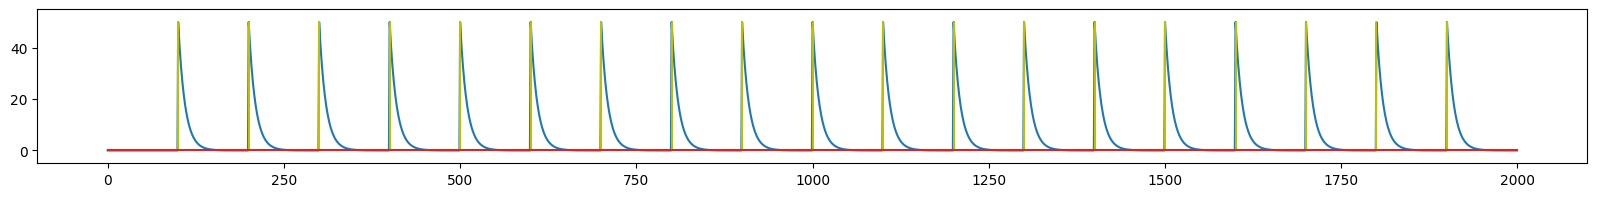

In [5]:
fig = plt.figure(figsize=(20, 2))
plt.plot(series[:2000])
plt.ylim(series.min() - 5, series.max() + 5)

plt.stem(spikes[:2000] * amplitude, markerfmt=",", linefmt="y")

<StemContainer object of 3 artists>

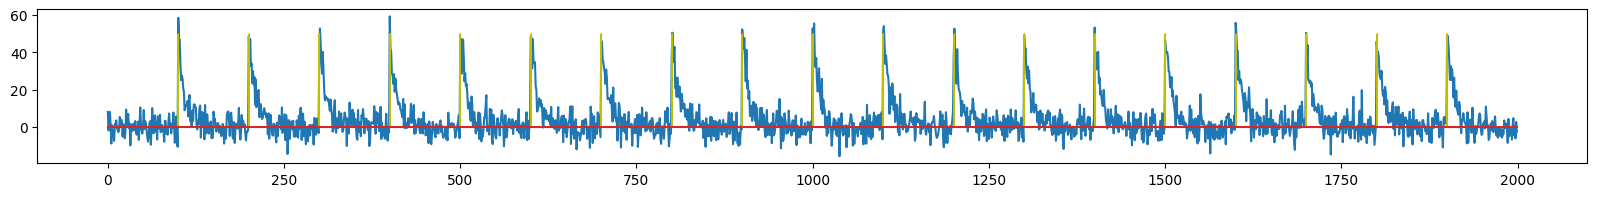

In [6]:
series_noise = series + np.random.normal(scale=5, size=series.size)

fig = plt.figure(figsize=(20, 2))
plt.plot(series_noise[:2000])

plt.stem(spikes[:2000] * amplitude, markerfmt=",", linefmt="y")

In [95]:
data = series_noise
data = data[::-1]

In [96]:
window_size = 10

In [97]:
def get_hankel(s: np.ndarray, timepoint: int, n_steps: int):
    h = np.zeros((n_steps, n_steps), dtype=np.float32)
    for i in range(n_steps):
        start = timepoint + i
        stop = start + n_steps
        h[i] = s[start:stop]

    return h

In [98]:
rolling_hankel_s0 = np.zeros(n_timepoints)
rolling_hankel_sgap = np.zeros(n_timepoints)
n_steps = window_size

for i in range(n_steps, n_timepoints - (n_steps * 2)):
    h = get_hankel(data, timepoint=i - n_steps, n_steps=n_steps)
    u, s, v = svd(h)
    rolling_hankel_s0[i] = s[0]
    rolling_hankel_sgap[i] = s[0] - s[1]

rolling_hankel_s0 = rolling_hankel_s0[::-1]
rolling_hankel_sgap = rolling_hankel_sgap[::-1]
data = data[::-1]

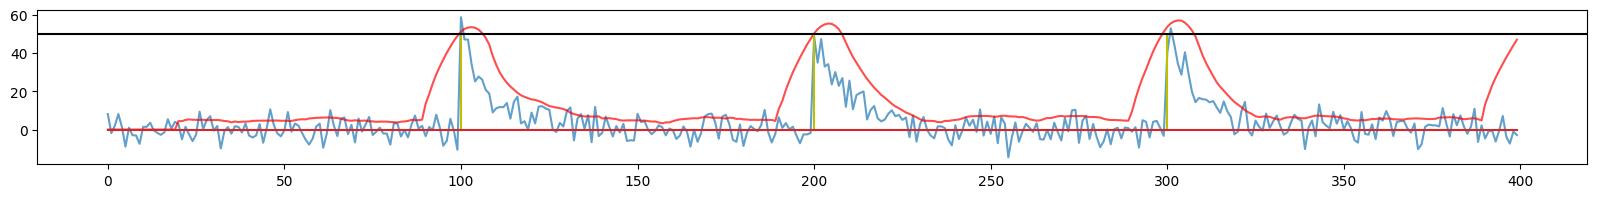

In [124]:
n_timepoints_plot = 400
fig = plt.figure(figsize=(20, 2))
plt.plot(data[:n_timepoints_plot], alpha=0.7)
scale_s0 = (rolling_hankel_s0.max() / data.max())
plt.plot(rolling_hankel_s0[:n_timepoints_plot] / scale_s0, color="r", alpha=0.7)
# plt.plot(rolling_hankel_sgap[:n_timepoints_plot] / (rolling_hankel_sgap.max() / amplitude), color="g", alpha=0.7)
plt.stem(spikes[:n_timepoints_plot] * amplitude, markerfmt=",", linefmt="y")

plt.axhline(rolling_hankel_s0.std() * 3 / scale_s0, c="k")

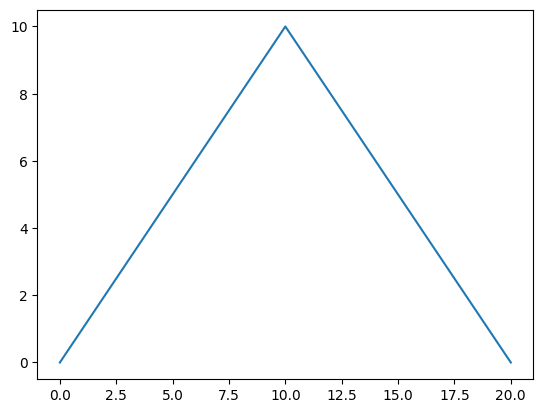

In [132]:
tent_filter_size = window_size * 2
tent_filter = np.concatenate([np.arange(0, stop=tent_filter_size / 2), np.arange(start=tent_filter_size / 2, stop=-1, step=-1)])
plt.plot(tent_filter)

In [133]:
tent_filtered = np.zeros(n_timepoints)

for i in range(data.size - tent_filter.size):
    tent_filtered[i + int(tent_filter.size / 2)] = np.dot(data[i:i + tent_filter.size], tent_filter) / np.linalg.norm(tent_filter, ord=2)

<StemContainer object of 3 artists>

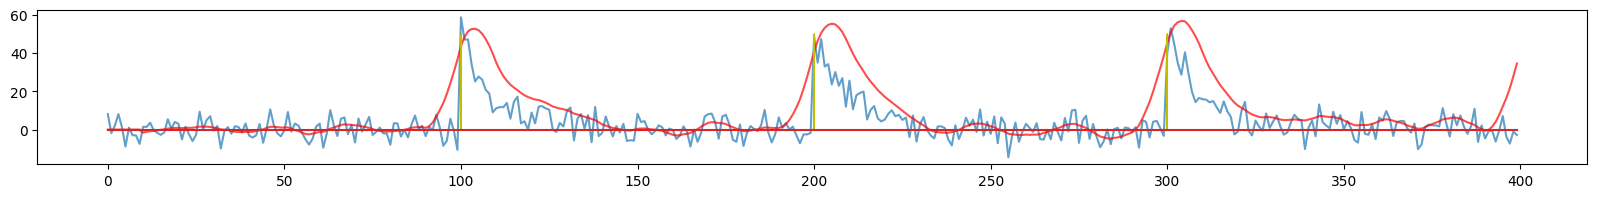

In [134]:
n_timepoints_plot = 400
fig = plt.figure(figsize=(20, 2))
plt.plot(data[:n_timepoints_plot], alpha=0.7)
scale = tent_filtered.max() / data.max()
plt.plot(tent_filtered[:n_timepoints_plot] / scale, color="r", alpha=0.7)
plt.stem(spikes[:n_timepoints_plot] * amplitude, markerfmt=",", linefmt="y")

# plt.axhline(rolling_hankel_s0.std() * 3 / scale_s0, c="k")